# Chest X-ray classification: COVID-19, Normal, Pneumonia, Tuberculosis

This notebook **shows and explains** the results. The code lives in the `chestxray/` package:

| Module | Responsibility |
|---|---|
| `config.py` | all paths and hyperparameters |
| `data.py` | loading images, patient IDs, patient-grouped stratified split |
| `preprocessing.py` | white balance |
| `duplicates.py` | finding near-identical images |
| `audit.py` | dataset checks: duplicates and non-medical shortcuts |
| `pipeline.py` | `tf.data` input pipeline and augmentation |
| `model.py` | MobileNetV2 transfer-learning model |
| `train.py` | two-phase training, command line: `python -m chestxray.train --seed 0` |
| `evaluate.py` | metrics (accuracy, F1, ROC-AUC) and plots |
| `gradcam.py` | Grad-CAM heatmaps |

Training takes about 30 minutes per run on a CPU, so it is done with the command line script; this notebook loads the saved results from `results/`.

In [1]:
import json
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from tensorflow import keras

from chestxray.config import Config
from chestxray.data import load_dataset, split_by_patient
from chestxray.duplicates import duplicate_sets, merge_groups
from chestxray.evaluate import plot_confusion_matrix, plot_history, plot_roc_curves
from chestxray.gradcam import grad_cam, overlay
from chestxray.preprocessing import white_balance
from from_scratch import equalize_histogram, sobel_edges

config = Config()
RESULTS = Path("results")
SEEDS = (0, 1, 2)
rng = np.random.default_rng(0)

## 1. Data

[Chest X-Ray (Pneumonia, Covid-19, Tuberculosis)](https://www.kaggle.com/datasets/jtiptj/chest-xray-pneumoniacovid19tuberculosis) from Kaggle, merged by `download_data.py` into one folder per class. `load_dataset` reads every image, resizes it to 224×224, converts BGR to RGB (Keras models expect RGB) and applies white balance. The result is cached in `data/cache_224.npz`, so later runs load in seconds.

In [2]:
data = load_dataset(config)
counts = pd.Series(data.labels).value_counts().reindex(config.classes)
print(f"{len(data.labels)} images, {data.images.shape[1:]} each, {data.images.dtype}")
counts.to_frame("images")

7135 images, (224, 224, 3) each, uint8


,images
COVID19,576
NORMAL,1583
PNEUMONIA,4273
TUBERCULOSIS,703


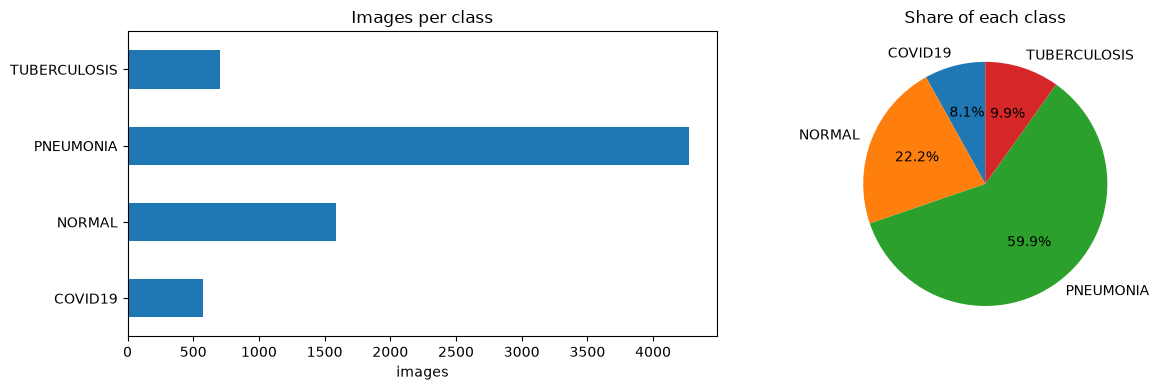

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
counts.plot.barh(ax=ax[0], color="tab:blue", title="Images per class")
ax[0].set_xlabel("images")
ax[1].pie(counts, labels=counts.index, autopct="%1.1f%%", startangle=90)
ax[1].set_title("Share of each class")
plt.tight_layout()

The classes are **imbalanced**: Pneumonia is 60% of the data. A model that always says "Pneumonia" is already 60% accurate, so accuracy alone is misleading. That is why training uses balanced **class weights** and the evaluation reports **macro F1** (every class counts equally).

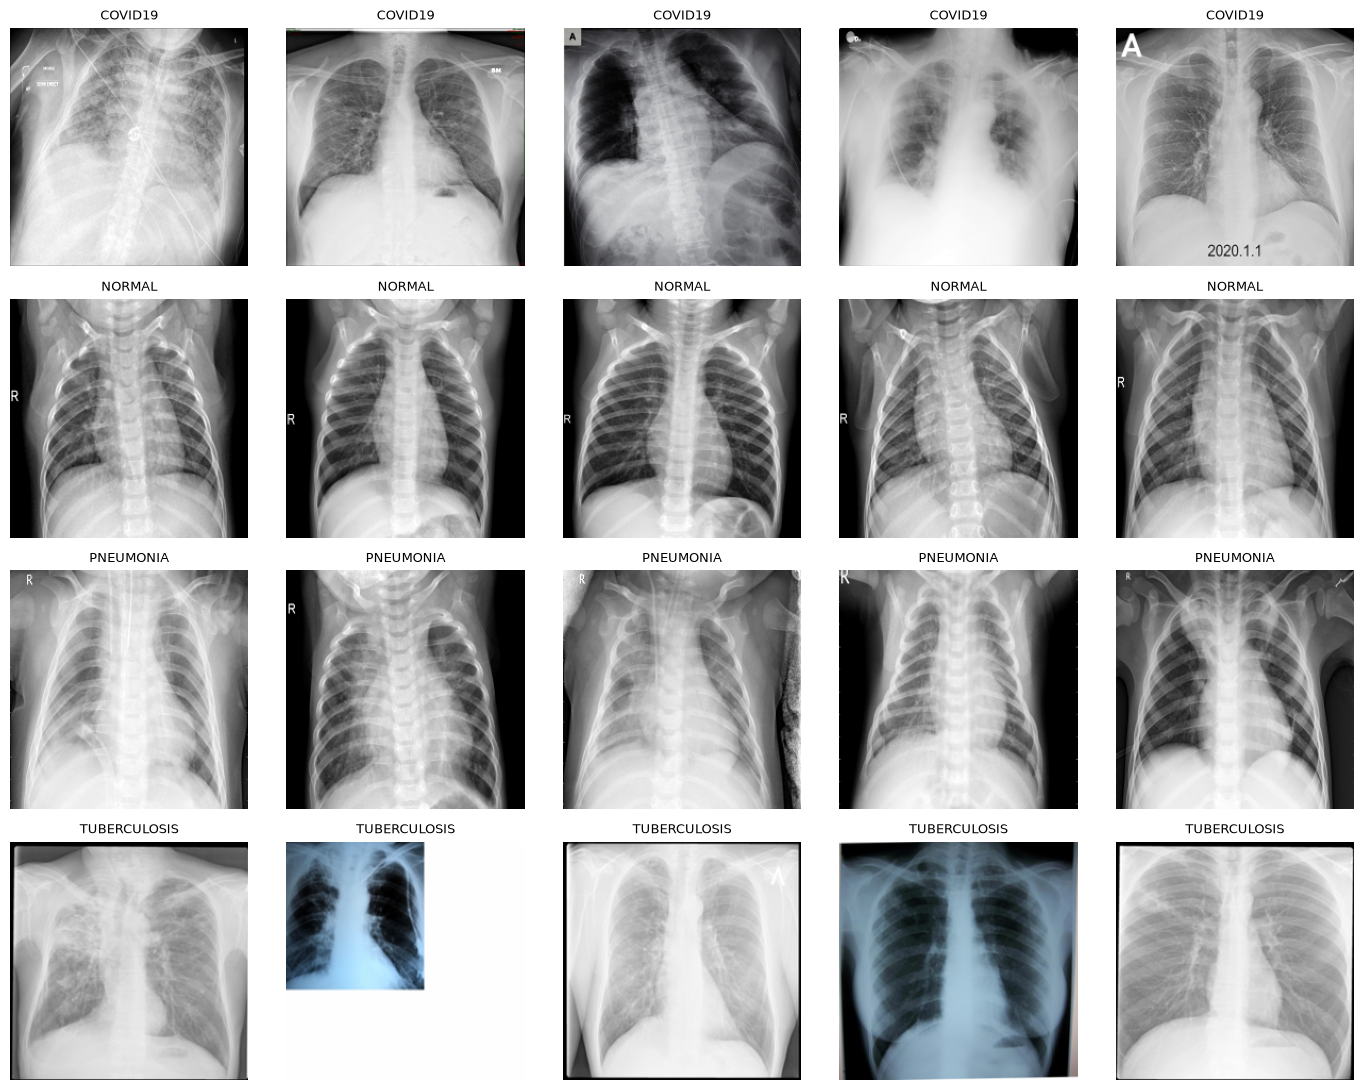

In [4]:
fig, axes = plt.subplots(len(config.classes), 5, figsize=(14, 11))
for row, name in zip(axes, config.classes):
    for ax, index in zip(row, rng.choice(np.flatnonzero(data.labels == name), 5, replace=False)):
        ax.imshow(data.images[index])
        ax.set_title(name, fontsize=9)
        ax.axis("off")
plt.tight_layout()

### White balance

Each channel is stretched so that its 0.05th percentile becomes 0 and its 99.95th percentile becomes 255. Air-filled lungs stay dark, bone and tissue become brighter, and differences in exposure between scanners shrink.

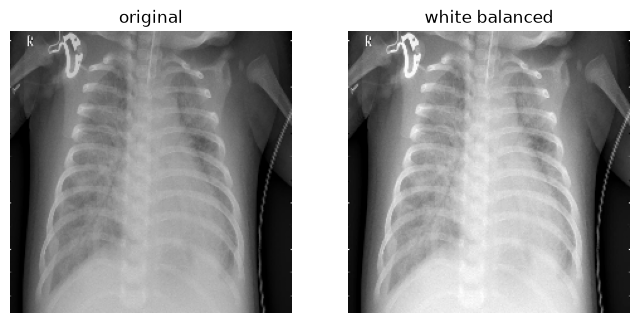

In [5]:
path = data.paths[np.flatnonzero(data.labels == "PNEUMONIA")[0]]
raw = cv2.cvtColor(cv2.resize(cv2.imread(path), (224, 224)), cv2.COLOR_BGR2RGB)
fig, ax = plt.subplots(1, 2, figsize=(8, 4))
for axis, image, title in zip(ax, (raw, white_balance(raw)), ("original", "white balanced")):
    axis.imshow(image)
    axis.set_title(title)
    axis.axis("off")

## 2. Dataset audit: is the task as clean as it looks?

`python -m chestxray.audit` checks three things. See `docs/dataset_audit.md` for the discussion.

In [6]:
audit = json.loads((RESULTS / "audit.json").read_text())
pd.DataFrame(audit["per_class"]).T

,images,patients,max_images_per_patient,file_types,median_height,median_width
COVID19,576,576,1,{'.jpg': 576},1028,1165
NORMAL,1583,1444,4,{'.jpeg': 1583},1323,1654
PNEUMONIA,4273,1674,31,{'.jpeg': 4273},776,1160
TUBERCULOSIS,703,703,1,{'.png': 703},512,512


In [7]:
probes = {
    "always predict the largest class": audit["majority_class_accuracy"],
    "random forest on brightness/contrast only": audit["probe_accuracy_brightness_only"],
    "random forest on original image size only": audit["probe_accuracy_size_only"],
    "random forest on size + brightness": audit["probe_accuracy_size_and_brightness"],
}
pd.Series(probes, name="accuracy (5-fold CV)").round(3).to_frame()

,accuracy (5-fold CV)
always predict the largest class,0.599
random forest on brightness/contrast only,0.687
random forest on original image size only,0.835
random forest on size + brightness,0.900


**Findings**

1. **Each class comes from a different source**, with its own file type and image size: Tuberculosis images are all 512×512 PNG files, Normal and Pneumonia are pediatric JPEGs from one hospital, COVID-19 images are JPGs from many sources. A random forest that sees **only the original image size and brightness — nothing medical —** already reaches about 90% accuracy. The CNN does not see the original size, but it can see brightness, contrast and resizing artefacts. So part of any high score may come from recognising the *source* rather than the *disease* (shortcut learning).
2. **Several images per patient**: Pneumonia has 4,273 images of 1,674 patients (up to 31 images of one patient). A random split would put the same patient in training and test.
3. **Near-identical images**: 52 sets of duplicates (109 images), 23 of them under different patient IDs, and one X-ray that appears **both as COVID-19 and as Pneumonia** — a labelling error in the dataset.

Therefore the split below keeps every patient, and every set of duplicates, in **one** of train/validation/test.

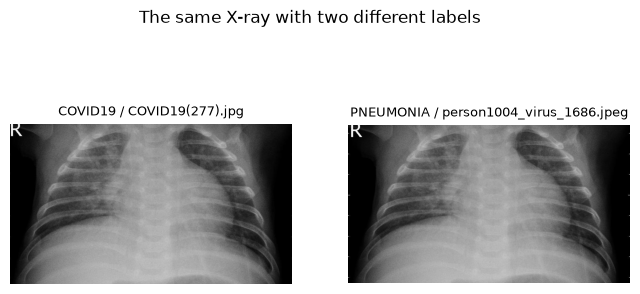

In [8]:
path_a, path_b = audit["duplicate_examples_across_classes"][0]
fig, ax = plt.subplots(1, 2, figsize=(8, 4))
for axis, path in zip(ax, (path_a, path_b)):
    axis.imshow(cv2.cvtColor(cv2.imread(path), cv2.COLOR_BGR2RGB))
    axis.set_title(Path(path).parent.name + " / " + Path(path).name, fontsize=9)
    axis.axis("off")
fig.suptitle("The same X-ray with two different labels");

## 3. Train / validation / test split

`split_by_patient` uses `StratifiedGroupKFold` twice: first 1/7 of the patients (≈14%) become the **test set**, then 1/6 of the rest (≈14%) the **validation set**; the remaining ≈71% is the **training set**. Stratified: the class proportions stay the same. Grouped: no patient (and no duplicate) is in two sets.

- The **validation set** is used during training: early stopping, learning-rate reduction and choosing the best checkpoint.
- The **test set** is used **once**, at the very end. Using it for model selection would leak information and make the score too optimistic.

In [9]:
groups = merge_groups(data.groups, duplicate_sets(data.images))
split = split_by_patient(data.labels, groups, config.val_fraction, config.test_fraction, seed=0)
sets = {"train": split.train, "validation": split.val, "test": split.test}
table = pd.DataFrame({name: pd.Series(data.labels[idx]).value_counts() for name, idx in sets.items()})
table.loc["total"] = table.sum()
table["share of test"] = (table["test"] / table["test"]["total"]).round(3)
table

,train,validation,test,share of test
PNEUMONIA,3052,611,610,0.598
NORMAL,1131,226,226,0.222
TUBERCULOSIS,502,100,101,0.099
COVID19,411,82,83,0.081
total,5096,1019,1020,1.000


In [10]:
shared = [set(groups[a]) & set(groups[b]) for a, b in
          [(split.train, split.test), (split.train, split.val), (split.val, split.test)]]
print("patients shared between sets:", [len(s) for s in shared])

patients shared between sets: [0, 0, 0]


## 4. Model and training

**MobileNetV2** pretrained on ImageNet, with a new head: `GlobalAveragePooling2D → Dense(256, ReLU) → Dropout(0.5) → Dense(4, softmax)`. A `Rescaling` layer maps the [0, 1] input to [-1, 1], the range MobileNetV2 was pretrained on.

Training has two phases (`chestxray/train.py`):
1. **Frozen backbone**, only the head learns (Adam, learning rate 1e-3).
2. **Fine-tuning** of the last 30 backbone layers with a 100× smaller learning rate (1e-5), so the pretrained features adapt without being destroyed.

Light augmentation (±10° rotation, ±5% shift, ±10% zoom; no horizontal flip because the heart is on the left) runs in a `tf.data` pipeline. Balanced class weights counter the imbalance.

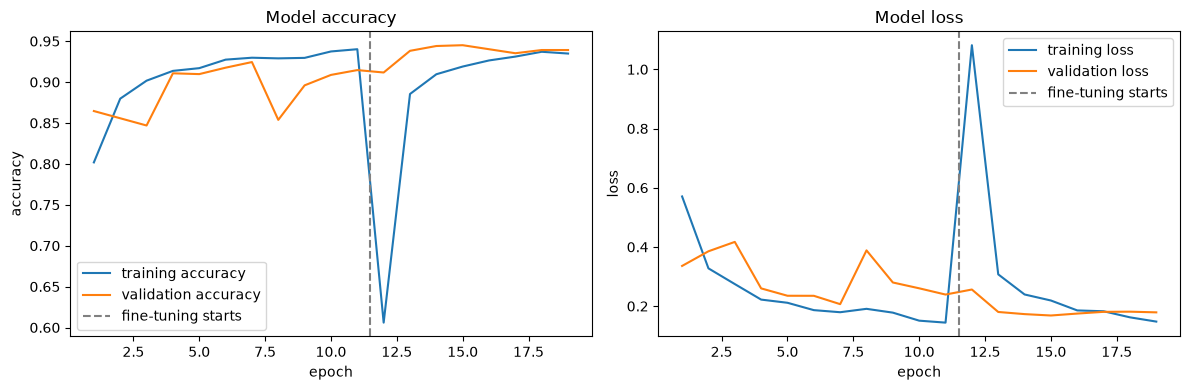

In [11]:
history = json.loads((RESULTS / "seed_0" / "history.json").read_text())
plot_history(history, history["phase1_epochs"])
plt.tight_layout()

## 5. Results on the test set (seed 0)

In [12]:
metrics = json.loads((RESULTS / "seed_0" / "metrics.json").read_text())
stored = np.load(RESULTS / "seed_0" / "split.npz")
probs = stored["test_probs"]
class_index = {name: i for i, name in enumerate(config.classes)}
y_test = np.array([class_index[label] for label in data.labels[stored["test"]]])

report = pd.DataFrame(metrics["report"]).T.drop(columns="support", errors="ignore")
print(f"accuracy {metrics['accuracy']:.3f} | macro F1 {metrics['macro_f1']:.3f} | "
      f"macro ROC-AUC {metrics['roc_auc_macro']:.3f}")
report.round(3)

accuracy 0.938 | macro F1 0.929 | macro ROC-AUC 0.994


,precision,recall,f1-score
COVID19,0.870,0.964,0.914
NORMAL,0.846,0.969,0.903
PNEUMONIA,0.983,0.930,0.955
TUBERCULOSIS,0.989,0.901,0.943
accuracy,0.938,0.938,0.938
macro avg,0.922,0.941,0.929
weighted avg,0.944,0.938,0.939


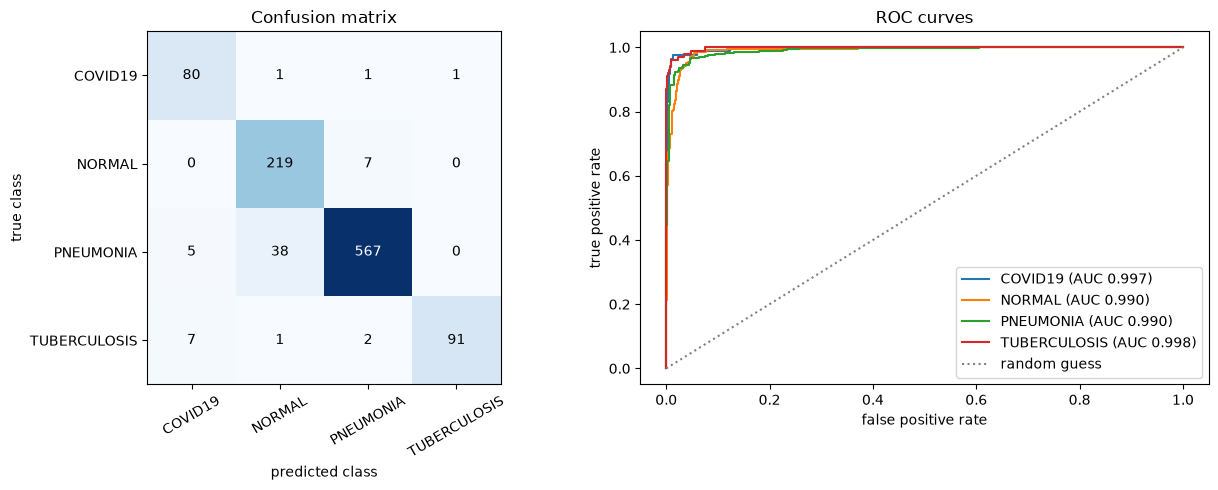

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
plot_confusion_matrix(metrics["confusion_matrix"], config.classes, ax=ax[0])
plot_roc_curves(y_test, probs, config.classes, ax=ax[1])
plt.tight_layout()

## 6. How stable is the result? Three runs with different seeds

The seed changes the split, the initial weights of the head, the augmentation and the batch order. One number from one run can be lucky; the mean and standard deviation over three runs are more honest.

In [14]:
runs = {f"seed {s}": json.loads((RESULTS / f"seed_{s}" / "metrics.json").read_text()) for s in SEEDS}
summary = pd.DataFrame({
    name: {
        "accuracy": m["accuracy"],
        "macro F1": m["macro_f1"],
        "macro ROC-AUC": m["roc_auc_macro"],
        **{f"F1 {c}": m["report"][c]["f1-score"] for c in config.classes},
    }
    for name, m in runs.items()
}).T
summary.loc["mean"] = summary.mean()
summary.loc["std"] = summary.iloc[:len(SEEDS)].std()
summary.round(3)

,accuracy,macro F1,macro ROC-AUC,F1 COVID19,F1 NORMAL,F1 PNEUMONIA,F1 TUBERCULOSIS
seed 0,0.938,0.929,0.994,0.914,0.903,0.955,0.943
seed 1,0.919,0.912,0.992,0.913,0.873,0.939,0.921
seed 2,0.937,0.933,0.994,0.940,0.894,0.954,0.944
mean,0.931,0.924,0.993,0.922,0.890,0.949,0.936
std,0.011,0.011,0.001,0.015,0.015,0.009,0.013


## 7. Grad-CAM: where does the model look?

Grad-CAM weights the backbone's last 7×7 feature maps by the gradient of the class score and shows the result as a heatmap. Red areas pushed the prediction towards the shown class. A trustworthy model should look at the **lungs**, not at text markers, borders or the corners of the image.

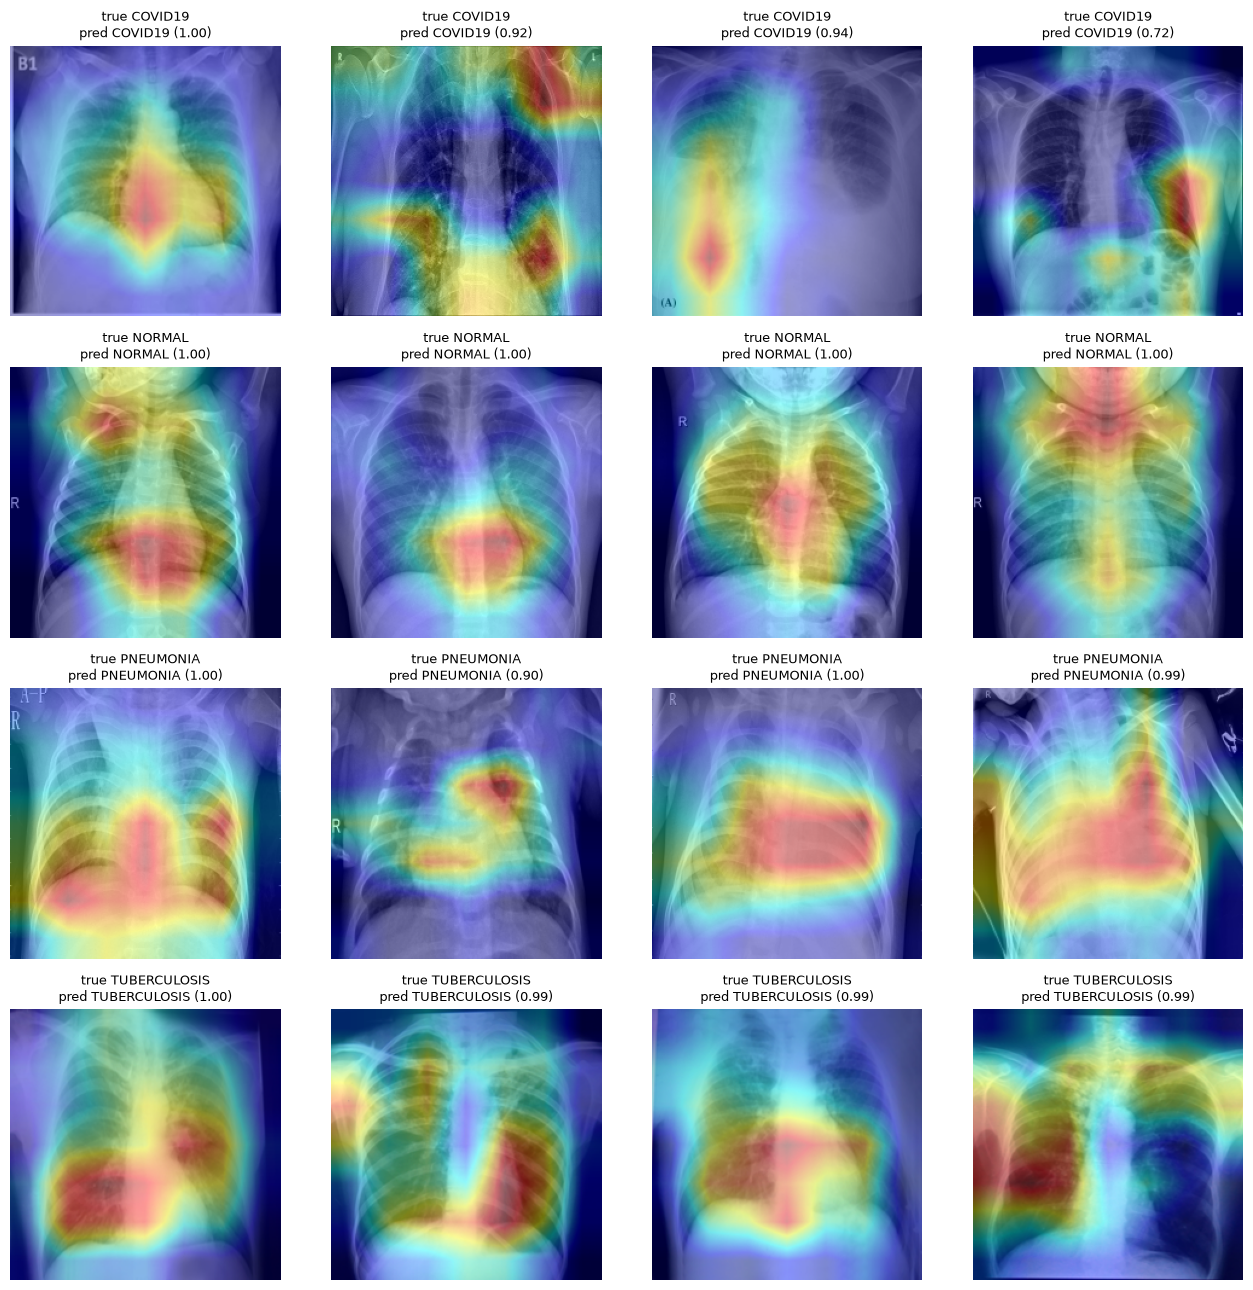

In [15]:
model = keras.models.load_model(RESULTS / "seed_0" / "best_model.keras")
test_idx = stored["test"]
fig, axes = plt.subplots(len(config.classes), 4, figsize=(13, 13))
for row, name in zip(axes, config.classes):
    for ax, index in zip(row, rng.choice(test_idx[data.labels[test_idx] == name], 4, replace=False)):
        heatmap, class_probs, predicted = grad_cam(model, data.images[index])
        ax.imshow(overlay(data.images[index], heatmap))
        ax.set_title(f"true {name}\npred {config.classes[predicted]} ({class_probs[predicted]:.2f})", fontsize=9)
        ax.axis("off")
plt.tight_layout()

## 8. Masking experiment: does the model need the lungs?

The audit showed that non-medical features alone predict the class with ~90% accuracy. To test what the CNN relies on, the same model (frozen backbone, head only, same split) is trained three times, each time seeing a different part of the image:

- **all**: the whole image;
- **lungs**: only a central ellipse that covers both lungs, everything else black;
- **outside**: the opposite — the lungs are blacked out, only borders, corners, shoulders and text markers remain.

If "outside" still scores high, the classes can be told apart **without looking at the lungs**, which is strong evidence of shortcut learning.

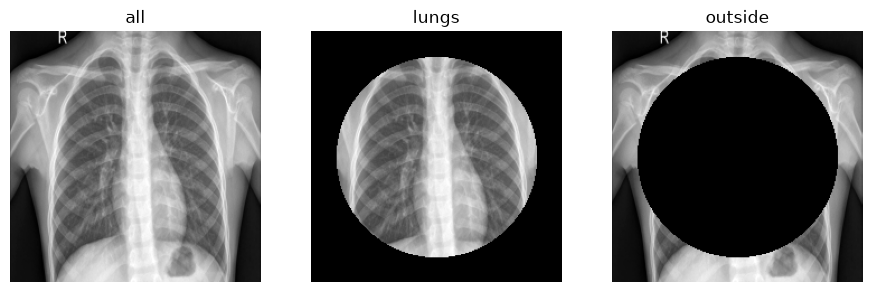

In [16]:
from chestxray.pipeline import region_mask

example = data.images[np.flatnonzero(data.labels == "NORMAL")[0]]
fig, ax = plt.subplots(1, 3, figsize=(11, 4))
for axis, region in zip(ax, ("all", "lungs", "outside")):
    mask = region_mask(224, region)
    axis.imshow(example if mask is None else (example * mask).astype(np.uint8))
    axis.set_title(region)
    axis.axis("off")

In [17]:
masking = {
    region: json.loads((RESULTS / f"masking_{region}" / "metrics.json").read_text())
    for region in ("all", "lungs", "outside")
}
pd.DataFrame({
    region: {
        "accuracy": m["accuracy"],
        "macro F1": m["macro_f1"],
        "macro ROC-AUC": m["roc_auc_macro"],
        **{f"F1 {c}": m["report"][c]["f1-score"] for c in config.classes},
    }
    for region, m in masking.items()
}).T.round(3)

,accuracy,macro F1,macro ROC-AUC,F1 COVID19,F1 NORMAL,F1 PNEUMONIA,F1 TUBERCULOSIS
all,0.927,0.914,0.992,0.906,0.889,0.948,0.914
lungs,0.934,0.919,0.991,0.904,0.887,0.957,0.927
outside,0.889,0.854,0.980,0.768,0.847,0.928,0.871


**Result.** With the lungs blacked out (*outside*), the model still reaches **0.889 accuracy and 0.854 macro F1** — far above the 0.599 of always guessing Pneumonia. The classes can be told apart **without seeing the lungs**: image borders, shoulders, framing and text markers carry most of the class information. This confirms the audit: the dataset contains strong shortcuts.

At the same time, *lungs only* (0.934 / 0.919) is as good as the full image (0.928 / 0.914), so the lung region alone is enough too. Together with the Grad-CAM maps this suggests that the model does use the lungs — but we cannot rule out that it also uses source-specific cues. COVID-19 suffers most when the lungs are hidden (F1 0.906 → 0.768).

## 9. A neural network written from scratch (NumPy)

`from_scratch/neural_net.py` implements a multi-layer perceptron without any deep-learning library: dense layers (`z = xW + b`), ReLU, softmax with weighted cross-entropy, **backpropagation** with the chain rule and gradient descent with momentum. `tests/test_neural_net.py` checks every analytic gradient against a numerical (central-difference) gradient.

`python -m from_scratch.train_on_xrays` trains it (1024 → 256 → 64 → 4) on 32×32 gray versions of the same images, with the same patient-grouped split, and keeps the epoch with the best validation macro F1.

,accuracy,macro_f1,roc_auc_macro
"NumPy MLP (32x32, from scratch)",0.946,0.928,0.988
"MobileNetV2 (224x224, fine-tuned)",0.938,0.929,0.994


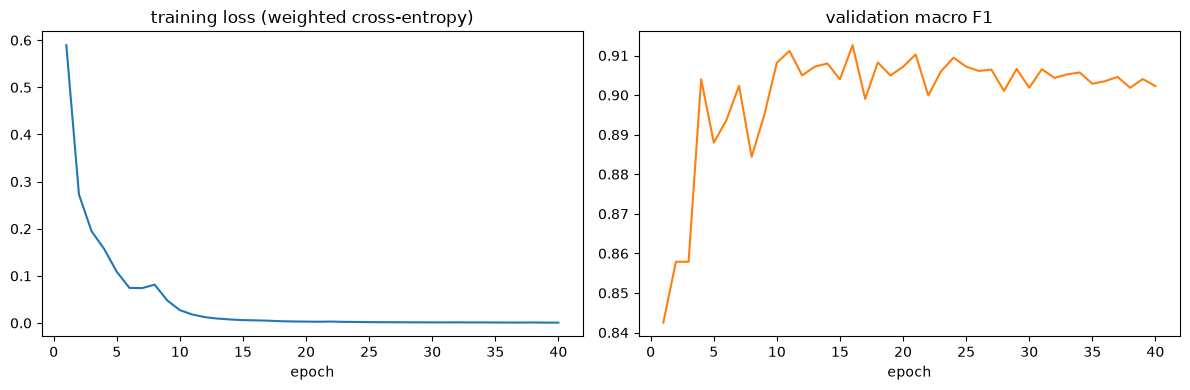

In [18]:
mlp = json.loads((RESULTS / "mlp_from_scratch.json").read_text())
mlp_history = pd.DataFrame(mlp["history"]).set_index("epoch")
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
mlp_history["loss"].plot(ax=ax[0], title="training loss (weighted cross-entropy)")
mlp_history["val_macro_f1"].plot(ax=ax[1], title="validation macro F1", color="tab:orange")
for axis in ax:
    axis.set_xlabel("epoch")
plt.tight_layout()
cnn = json.loads((RESULTS / "seed_0" / "metrics.json").read_text())
pd.DataFrame({
    "NumPy MLP (32x32, from scratch)": {k: mlp["test"][k] for k in ("accuracy", "macro_f1", "roc_auc_macro")},
    "MobileNetV2 (224x224, fine-tuned)": {k: cnn[k] for k in ("accuracy", "macro_f1", "roc_auc_macro")},
}).T.round(3)

**Result.** A from-scratch MLP that sees only **32×32** gray values reaches **0.946 accuracy and 0.928 macro F1** on the same test set — about the same as the fine-tuned MobileNetV2 (seed 0: 0.938 / 0.929). A network that sees no fine detail can hardly read subtle lung patterns, so this is one more sign that on this dataset the classes differ in coarse, global properties (source, framing, brightness).

The training loss goes almost to 0 while validation macro F1 stays around 0.90: the MLP overfits, which is why the epoch is chosen on the validation set.

## 10. Classic algorithms written from scratch (NumPy)

`from_scratch/` implements histogram equalization (histogram → CDF → lookup table) and Sobel edge detection (2-D correlation, gradient magnitude) without OpenCV. The unit tests in `tests/` check them against `cv2.equalizeHist` and `cv2.Sobel`.

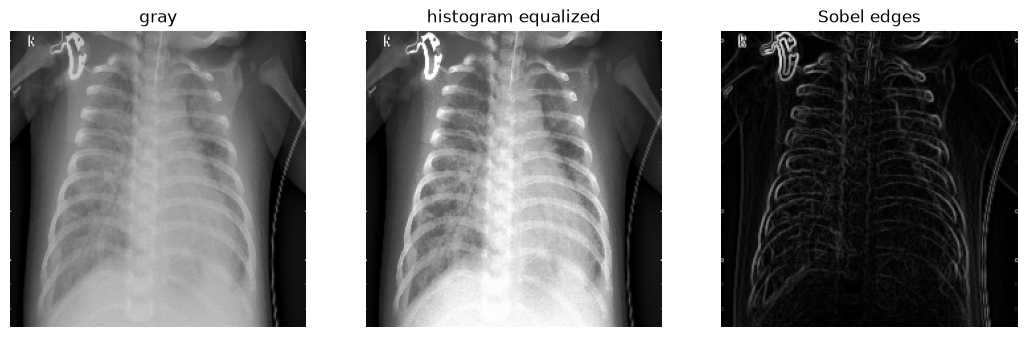

In [19]:
gray = cv2.cvtColor(raw, cv2.COLOR_RGB2GRAY)
equalized = equalize_histogram(gray)
edges, _ = sobel_edges(equalized)
fig, ax = plt.subplots(1, 3, figsize=(13, 4))
for axis, image, title in zip(ax, (gray, equalized, edges), ("gray", "histogram equalized", "Sobel edges")):
    axis.imshow(image, cmap="gray")
    axis.set_title(title)
    axis.axis("off")

## 11. Conclusions and limitations

- With a split grouped by patient and by duplicate image, the fine-tuned MobileNetV2 reaches **accuracy 0.931 ± 0.011, macro F1 0.924 ± 0.011 and macro ROC-AUC 0.993 ± 0.001** (mean ± standard deviation over 3 seeds).
- The weakest class is **Normal** (F1 0.890 ± 0.015, precision 0.82). Most errors are Pneumonia X-rays predicted as Normal (38 of 610 in seed 0) — in a medical setting the costly kind of error, because a sick patient would be missed.
- **The scores measure this dataset, not clinical performance.** The audit (a random forest on size and brightness: 0.90 accuracy), the masking experiment (0.889 accuracy with the lungs hidden) and the 32×32 NumPy MLP (0.946 accuracy) all show that the classes can be separated by cues that are not medical, because every class comes from a different source.
- Grad-CAM mostly highlights the chest, which is encouraging, but it is too coarse (7×7) to exclude global cues such as brightness or framing.

**What would make the result trustworthy:** an external test set from another hospital in which all four classes come from the same source; lung segmentation masks instead of a fixed ellipse; and a decision threshold for *Normal* chosen to miss fewer sick patients.